# WiPER Benchmarking — v11: azione, fase e rete neurale

Stesso protocollo di v7–v10: k-fold sulle identità (33 train / 11 test), 4 protocolli per registrazione (`cross`, `cross_rev`, `same_saluto`, `same_tpose`), chance esatta per Rank-1 e mAP. Legge ampiezze e `csi_matrices` prodotte da *WiPER-DataProcessing*.

**Perché la v11.** Con le feature handcrafted + LDA siamo a un plateau (~38 mAP media sui 4 protocolli; Rank-1 `cross` ≈ 33–37%, `same_saluto` ≈ 43–54%). Il divario più grande misurato è fra **stesso-azione e cross-azione**. Restano due leve:

| # | Cosa | Sezione |
|---|---|---|
| 1 | **Cross-azione, senza fuga di informazione** (si stima tutto sul training e si applica uguale a tutti): standardizzazione *per azione*, centratura per azione, rimozione del sottospazio che separa le due azioni (con controllo: stesso numero di direzioni casuali) | §4 |
| 2 | **GAT a 1 o 2 canali** (ampiezza, fase classica, ampiezza+fase) con **batch bilanciati per azione** (ogni identità porta registrazioni di entrambe le azioni, quindi la loss triplet vede il cambio saluto↔tPose). Stesso CV e stesse metriche del baseline LDA | §5–§6 |

La colonna **gap** = mAP media `same_*` − mAP media `cross*`: misura quanto il cambio di azione costa. Se un metodo la riduce senza abbassare `same_*`, risolve davvero il problema cross-azione.

**Tempi.** La parte neurale addestra `len(runs) × n_folds` modelli. Dopo la prima epoca il notebook stima la durata totale. I risultati di ogni (run, fold) vengono salvati in `output/v11_neural_results.pkl`: se interrompi, riesegui e riparte da dove era arrivato (`resume=True`). Per una prova veloce: `n_epochs=5`, `neural_folds=1`.

## 1. Imports e configurazione

In [1]:
import os, re, random, time, pickle
from collections import defaultdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from torch_geometric.nn import GATConv, global_mean_pool, global_max_pool

pd.set_option('display.max_columns', None); pd.set_option('display.width', 250)

CFG = dict(
    seed=42,
    output_folder='./output/',
    sanitization='zscore',            # ampiezze: 'raw' | 'hampel' | 'zscore' | 'iqr'
    exclude_ids=('vuoto',),
    gallery_action='saluto', probe_action='tpose',
    n_subcarriers=52, n_packets=100, stride=25,
    phase_outlier_z=3.0,
    n_folds=4,
    # --- cross-azione (feature) ---
    action_k=(1, 3, 6),               # direzioni di "differenza fra azioni" da rimuovere
    n_ctrl=3,                         # controlli con direzioni casuali
    # --- rete neurale ---
    run_neural=True,
    neural_runs=['GAT amp', 'GAT phase', 'GAT amp+phase'],     # vedi NEURAL_RUNS nella §5
    include_unbalanced_ablation=False,   # True: aggiunge 'GAT amp+phase (batch NON bilanciati)'
    neural_folds=None,                # None = tutti i fold; 1 = solo il primo (prova veloce)
    n_epochs=40, batches_per_epoch=20, P=8, K=4,
    lr=3e-4, weight_decay=5e-4, grad_clip=1.0,
    temporal_dim=64, hidden=64, heads=4, gat_out=128, emb_dim=128, dropout=0.2, band_k=4,
    margin=0.3, ce_weight=1.0, label_smoothing=0.1, lambda_gc=0.005, augment=True,
    device='auto',                    # 'auto' = cuda se disponibile, altrimenti cpu ('mps' solo se lo imposti a mano: PyG non copre tutte le operazioni)
    resume=True,
)

SANITIZATION_DIRS = {
    'raw':    ('CSV', 'raw_amplitudes'),
    'hampel': ('CSV', 'sanitized_amplitudes', 'HF_amplitudes'),
    'zscore': ('CSV', 'sanitized_amplitudes', 'zscore_amplitudes'),
    'iqr':    ('CSV', 'sanitized_amplitudes', 'iqr_amplitudes'),
}
amp_dir = os.path.join(CFG['output_folder'], *SANITIZATION_DIRS[CFG['sanitization']])
csi_dir = os.path.join(CFG['output_folder'], 'CSV', 'csi_matrices')

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

set_seed(CFG['seed'])
device = torch.device('cuda' if (CFG['device'] == 'auto' and torch.cuda.is_available()) else ('cpu' if CFG['device'] == 'auto' else CFG['device']))
print('device:', device)

device: cpu


## 2. Caricamento, fase classica, fold

In [2]:
KEY_RE = re.compile(r'^(?P<sid>[^_]+)_(?P<act>[A-Za-z]+)(?P<num>\d+)$')
assert os.path.isdir(amp_dir), f'Cartella non trovata: {amp_dir}'
assert os.path.isdir(csi_dir), f'Cartella non trovata: {csi_dir}'

def load_amp(key):
    return pd.read_csv(os.path.join(amp_dir, key + '.csv')).drop(columns='timestamp', errors='ignore').to_numpy(dtype=np.float64)

def load_csi(key):
    df = pd.read_csv(os.path.join(csi_dir, key + '.csv')).drop(columns='timestamp', errors='ignore')
    return df.to_numpy().astype(str).astype(complex)

def phase_residual(H):
    # srotola lungo le sottoportanti, toglie offset e pendenza lineare per pacchetto
    ph = np.unwrap(np.angle(H), axis=1)
    k = np.arange(H.shape[1]).astype(float); kc = k - k.mean()
    slope = (ph * kc).sum(axis=1) / (kc ** 2).sum()
    icpt = ph.mean(axis=1) - slope * k.mean()
    return ph - (slope[:, None] * k[None, :] + icpt[:, None])

def zscore_fill(M, thr):
    if thr is None: return M
    mu, sd = M.mean(0), M.std(0) + 1e-12
    return pd.DataFrame(M).mask(np.abs((M - mu) / sd) > thr).ffill().bfill().to_numpy()

recs = []
for fname in sorted(os.listdir(amp_dir)):
    if not fname.endswith('.csv'): continue
    key = fname[:-4]
    if key.split('_')[0] in CFG['exclude_ids']: continue
    m = KEY_RE.match(key)
    if not m: print('ignorato:', key); continue
    A, H = load_amp(key), load_csi(key)
    assert A.shape == H.shape == (A.shape[0], CFG['n_subcarriers']), f'{key}: forme incoerenti {A.shape} vs {H.shape}'
    recs.append(dict(sid=m.group('sid'), act=m.group('act').lower(), num=int(m.group('num')), rec_id=key,
                     A=A, P=zscore_fill(phase_residual(H), CFG['phase_outlier_z'])))

R = len(recs)
rec_sid = np.array([r['sid'] for r in recs]); rec_act = np.array([r['act'] for r in recs])
GAL, PRB = CFG['gallery_action'], CFG['probe_action']
assert GAL in set(rec_act) and PRB in set(rec_act)
print(f'{R} registrazioni | {len(set(rec_sid))} identità | azioni {sorted(set(map(str, rec_act)))}')

def natural_key(s): return [int(t) if t.isdigit() else t for t in re.split(r'(\d+)', s)]
all_ids = sorted(set(rec_sid), key=natural_key)
rng = np.random.RandomState(CFG['seed']); perm = rng.permutation(len(all_ids))
fold_ids = [set(all_ids[i] for i in chunk) for chunk in np.array_split(perm, CFG['n_folds'])]
folds = [(np.where(~np.isin(rec_sid, list(t)))[0], np.where(np.isin(rec_sid, list(t)))[0]) for t in fold_ids]
print('Fold (identità test / train):', [(len(t), len(set(rec_sid[tr]))) for t, (tr, _) in zip(fold_ids, folds)])

440 registrazioni | 44 identità | azioni ['saluto', 'tpose']
Fold (identità test / train): [(11, 33), (11, 33), (11, 33), (11, 33)]


## 3. Feature handcrafted, metriche e protocolli

In [3]:
def feature_groups(A, P):
    X = A / (A.mean() + 1e-8)
    return {'static': X.mean(0), 'dyn_std': X.std(0), 'diff': np.abs(np.diff(X, axis=0)).mean(0),
            'ph_static': P.mean(0), 'ph_std': P.std(0), 'ph_diff': np.abs(np.diff(P, axis=0)).mean(0)}

fw = defaultdict(list)
for r in recs:
    for k, v in feature_groups(r['A'], r['P']).items(): fw[k].append(v)
feat = {k: np.stack(v) for k, v in fw.items()}
FEATURE_SETS = {'amp static': ['static'], 'ph all': ['ph_static', 'ph_std', 'ph_diff'],
                'amp basic + ph all': ['static', 'dyn_std', 'diff', 'ph_static', 'ph_std', 'ph_diff']}
XS = {n: np.concatenate([feat[g] for g in gs], axis=1) for n, gs in FEATURE_SETS.items()}
print({n: x.shape[1] for n, x in XS.items()})

def expected_ap_random(n, p):
    if n <= 1: return 1.0
    i = np.arange(1, n + 1)
    return float(np.sum((1.0 / i) * (1 + (i - 1) * (p - 1) / (n - 1))) / n)

def rank_metrics(q_feats, q_ids, g_feats, g_ids, exclude_self=False):
    sim = q_feats @ g_feats.T
    q_ids, g_ids = np.asarray(q_ids), np.asarray(g_ids)
    matches = q_ids[:, None] == g_ids[None, :]
    if exclude_self:
        np.fill_diagonal(sim, -np.inf); np.fill_diagonal(matches, False)
    valid = matches.sum(1) > 0
    sim, matches = sim[valid], matches[valid]
    if len(sim) == 0:
        return dict(rank1=np.nan, rank5=np.nan, mAP=np.nan, n_queries=0, chance_rank1=np.nan, chance_mAP=np.nan)
    order = np.argsort(-sim, axis=1, kind='stable')
    m = np.take_along_axis(matches, order, axis=1)
    cum = np.cumsum(m, axis=1)
    cmc = (cum > 0).mean(axis=0) * 100.0
    ap = ((cum / (np.arange(m.shape[1]) + 1)) * m).sum(axis=1) / m.sum(axis=1)
    n_gal = matches.shape[1] - (1 if exclude_self else 0); pos = matches.sum(1)
    return dict(rank1=cmc[0], rank5=cmc[min(4, len(cmc) - 1)], mAP=ap.mean() * 100.0, n_queries=len(sim),
                chance_rank1=(pos / n_gal).mean() * 100.0,
                chance_mAP=np.mean([expected_ap_random(n_gal, p) for p in pos]) * 100.0)

PROTOCOLS = ['cross', 'cross_rev', f'same_{GAL}', f'same_{PRB}']

def eval_protocols(E, sid, act):
    G, Pm = act == GAL, act == PRB
    return {'cross':       rank_metrics(E[Pm], sid[Pm], E[G],  sid[G]),
            'cross_rev':   rank_metrics(E[G],  sid[G],  E[Pm], sid[Pm]),
            f'same_{GAL}': rank_metrics(E[G],  sid[G],  E[G],  sid[G],  exclude_self=True),
            f'same_{PRB}': rank_metrics(E[Pm], sid[Pm], E[Pm], sid[Pm], exclude_self=True)}

def l2(Z): return Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-12)

def aggregate_folds(res_list):
    out = {}
    for k in PROTOCOLS:
        w = np.array([r[k]['n_queries'] for r in res_list], float)
        for m in ['rank1', 'mAP', 'chance_rank1', 'chance_mAP']:
            v = np.array([r[k][m] for r in res_list]); out[(k, m)] = float((w * v).sum() / w.sum())
    return out

def mean_map(res): return float(np.mean([res[k]['mAP'] for k in PROTOCOLS]))

def results_table(store):
    rows = []; ch = aggregate_folds(next(iter(store.values())))
    rows.append({'metodo': 'CHANCE', **{f'{k} {m}': ch[(k, key)] for k in PROTOCOLS for m, key in [('R1', 'chance_rank1'), ('mAP', 'chance_mAP')]}})
    for name, res in store.items():
        a = aggregate_folds(res)
        cross_m = np.mean([a[('cross', 'mAP')], a[('cross_rev', 'mAP')]]); same_m = np.mean([a[(f'same_{GAL}', 'mAP')], a[(f'same_{PRB}', 'mAP')]])
        rows.append({'metodo': name, **{f'{k} {m}': a[(k, key)] for k in PROTOCOLS for m, key in [('R1', 'rank1'), ('mAP', 'mAP')]},
                     'mAP media4': np.mean([a[(k, 'mAP')] for k in PROTOCOLS]), 'gap (same-cross) mAP': same_m - cross_m})
    return pd.DataFrame(rows).set_index('metodo').round(1)

chance_mean4 = np.mean([aggregate_folds([eval_protocols(l2(np.random.RandomState(0).randn(R, 4))[te], rec_sid[te], rec_act[te]) for tr, te in folds])[(k, 'chance_mAP')] for k in PROTOCOLS])
print('Chance mAP media4: %.1f' % chance_mean4)

{'amp static': 52, 'ph all': 156, 'amp basic + ph all': 312}
Chance mAP media4: 14.4


## 4. Cross-azione sulle feature (leak-free)

Tutte le trasformazioni sono stimate **solo sulle registrazioni di training** e applicate identiche a training e test. L'azione di ogni registrazione è nota nel protocollo (gallery = saluto, probe = tPose), quindi usarla per scegliere le statistiche è lecito; non si usano statistiche del test.

* `pooled`: baseline (standardizzazione unica).
* `centra per azione`: sottrae a ogni azione la propria media di training.
* `z per azione`: standardizza ogni azione con media e deviazione standard proprie.
* `rimuovi sottospazio azione k`: per ogni soggetto di training calcola `media(saluto) − media(tPose)`; le prime `k` direzioni principali di queste differenze (non centrate) sono "il cambio di azione". Le si proietta fuori. **Controllo**: stesso `k`, direzioni casuali ortonormali (media su `n_ctrl`): mostra quanto costa rimuovere `k` direzioni a caso.

In [4]:
def standardize(X, tr, mode):
    X = np.asarray(X, float); act = rec_act
    if mode == 'pooled':
        mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-8
        return (X - mu) / sd
    Z = np.empty_like(X)
    if mode == 'center':
        pooled_sd = np.concatenate([X[tr][act[tr] == a] - X[tr][act[tr] == a].mean(0) for a in np.unique(act)]).std(0) + 1e-8
    for a in np.unique(act):
        tra = tr[act[tr] == a]; m = act == a; mu = X[tra].mean(0)
        sd = (X[tra].std(0) + 1e-8) if mode == 'zscore' else pooled_sd
        Z[m] = (X[m] - mu) / sd
    return Z

def action_basis(Z, tr, k, rng_ctrl=None):
    d = Z.shape[1]
    if rng_ctrl is not None:                                           # controllo: k direzioni casuali ortonormali
        Q, _ = np.linalg.qr(rng_ctrl.randn(d, min(k, d))); return Q
    diffs = []
    for s in sorted(set(rec_sid[tr])):
        g = tr[(rec_sid[tr] == s) & (rec_act[tr] == GAL)]; p = tr[(rec_sid[tr] == s) & (rec_act[tr] == PRB)]
        if len(g) and len(p): diffs.append(Z[g].mean(0) - Z[p].mean(0))
    D = np.stack(diffs)
    _, S, Vt = np.linalg.svd(D, full_matrices=False)
    return Vt[:min(k, len(S))].T

def embed_variant(X, tr, mode, k=0, rng_ctrl=None):
    if mode in ('pooled', 'center', 'zscore'):
        Z = standardize(X, tr, mode)
    elif mode == 'subspace':
        Z = standardize(X, tr, 'pooled'); V = action_basis(Z, tr, k, rng_ctrl); Z = Z - (Z @ V) @ V.T
    else:
        raise ValueError(mode)
    lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto').fit(Z[tr], rec_sid[tr])
    return l2(lda.transform(Z))

def run_variant(X, mode, k=0, ctrl_seed=None):
    res = []
    for f, (tr, te) in enumerate(folds):
        rc = np.random.RandomState(ctrl_seed + f) if ctrl_seed is not None else None
        E = embed_variant(X, tr, mode, k, rc)
        res.append(eval_protocols(E[te], rec_sid[te], rec_act[te]))
    return res

store = {}; ctrl_rows = []
t0 = time.time()
for sname in FEATURE_SETS:
    X = XS[sname]
    store[f'{sname} | pooled (LDA)']        = run_variant(X, 'pooled')
    store[f'{sname} | centra per azione']   = run_variant(X, 'center')
    store[f'{sname} | z per azione']        = run_variant(X, 'zscore')
    for k in CFG['action_k']:
        store[f'{sname} | rimuovi sottospazio azione k={k}'] = run_variant(X, 'subspace', k)
        ctrl = [run_variant(X, 'subspace', k, ctrl_seed=1000 + c) for c in range(CFG['n_ctrl'])]
        a = [aggregate_folds(c) for c in ctrl]
        ctrl_rows.append({'feature': sname, 'k': k,
                          'cross mAP (media 2)': np.mean([np.mean([x[('cross', 'mAP')], x[('cross_rev', 'mAP')]]) for x in a]),
                          'same mAP (media 2)': np.mean([np.mean([x[(f'same_{GAL}', 'mAP')], x[(f'same_{PRB}', 'mAP')]]) for x in a]),
                          'mAP media4': np.mean([np.mean([x[(p, 'mAP')] for p in PROTOCOLS]) for x in a])})
print(f'{time.time() - t0:.0f}s')
print('=== Feature + LDA: cosa fa la correzione per azione (Rank-1 % / mAP %) ===')
display(results_table(store))
print('=== Controllo: rimozione di k direzioni CASUALI (stesso k) ===')
display(pd.DataFrame(ctrl_rows).set_index(['feature', 'k']).round(1))

8s
=== Feature + LDA: cosa fa la correzione per azione (Rank-1 % / mAP %) ===


,cross R1,cross mAP,cross_rev R1,cross_rev mAP,same_saluto R1,same_saluto mAP,same_tpose R1,same_tpose mAP,mAP media4,gap (same-cross) mAP
metodo,,,,,,,,,,
CHANCE,9.1,15.1,9.1,15.1,7.4,13.7,7.4,13.7,NaN,NaN
amp static | pooled (LDA),30.0,30.0,26.4,28.6,48.6,41.6,40.0,36.9,34.3,9.9
amp static | centra per azione,27.7,29.4,25.0,28.7,47.3,41.6,42.3,37.4,34.3,10.5
amp static | z per azione,27.3,29.3,25.5,28.8,43.6,41.1,39.1,36.3,33.9,9.7
amp static | rimuovi sottospazio azione k=1,24.5,26.3,24.1,25.5,39.1,35.7,35.5,30.8,29.6,7.4
amp static | rimuovi sottospazio azione k=3,20.0,24.7,25.9,25.1,31.4,31.0,28.6,26.4,26.8,3.8
amp static | rimuovi sottospazio azione k=6,20.0,22.5,21.4,22.5,24.5,28.1,20.5,22.9,24.0,3.0
ph all | pooled (LDA),31.8,33.1,33.2,32.6,50.5,46.5,41.4,41.2,38.4,11.0
ph all | centra per azione,30.9,32.9,31.8,32.5,51.8,47.0,40.9,41.1,38.4,11.3


=== Controllo: rimozione di k direzioni CASUALI (stesso k) ===


cross mAP (media 2)  same mAP (media 2)  mAP media4
feature            k                                                     
amp static         1                 29.0                38.9        33.9
                   3                 29.3                38.5        33.9
                   6                 29.0                38.4        33.7
ph all             1                 32.9                43.8        38.4
                   3                 32.8                43.8        38.3
                   6                 33.0                43.9        38.5
amp basic + ph all 1                 33.0                43.2        38.1
                   3                 32.9                43.2        38.1
                   6                 33.1                43.2        38.2

## 5. Rete neurale a 1 o 2 canali con batch bilanciati per azione

Il grafo ha 52 nodi (sottoportanti) con serie temporale di 100 pacchetti **per canale**: ampiezza e/o fase classica. Normalizzazione interna: ampiezza divisa per la media del grafo, fase divisa per la sua deviazione standard (per grafo). Augmentation: guadagno solo sull'ampiezza, rumore relativo, traslazione temporale e dropout di sottoportanti identici sui canali.

**Batch bilanciati:** per ogni identità del batch si pescano `K/2` registrazioni di ciascuna azione (una finestra casuale per registrazione). Così gli esempi positivi della triplet loss attraversano l'azione.

In [5]:
NEURAL_RUNS = {
    'GAT amp':                                {'channels': ['amp'],        'balanced': True},
    'GAT phase':                              {'channels': ['ph'],         'balanced': True},
    'GAT amp+phase':                          {'channels': ['amp', 'ph'],  'balanced': True},
    'GAT amp+phase (batch NON bilanciati)':   {'channels': ['amp', 'ph'],  'balanced': False},
}
run_names = list(CFG['neural_runs']) + (['GAT amp+phase (batch NON bilanciati)'] if CFG['include_unbalanced_ablation'] else [])
for rn in run_names: assert rn in NEURAL_RUNS, f'run sconosciuta: {rn}'
CH_INDEX = {'amp': 0, 'ph': 1}

def sliding_windows(arr, n, stride):
    return [arr[s:s + n] for s in range(0, arr.shape[0] - n + 1, stride)]

# --- finestre [52 nodi, 2 canali, 100 pacchetti] ---
win_list, win_rec = [], []
for ri, r in enumerate(recs):
    wa = sliding_windows(r['A'], CFG['n_packets'], CFG['stride']); wp = sliding_windows(r['P'], CFG['n_packets'], CFG['stride'])
    for a, p in zip(wa, wp):
        win_list.append(np.stack([a.T, p.T], axis=1)); win_rec.append(ri)
WIN = torch.tensor(np.stack(win_list), dtype=torch.float32)        # [Nw, 52, 2, 100]
win_rec = np.array(win_rec)
print('finestre:', tuple(WIN.shape))

def band_edges(n, k):
    src, dst = [], []
    for i in range(n):
        for j in range(max(0, i - k), min(n, i + k + 1)):
            if i != j: src.append(i); dst.append(j)
    return torch.tensor([src, dst], dtype=torch.long)

class WiFiGAT(nn.Module):
    def __init__(self, cfg, n_classes, chan_types):
        super().__init__()
        N, T = cfg['n_subcarriers'], cfg['n_packets']
        self.N, self.T, self.chan_types, self.C = N, T, list(chan_types), len(chan_types)
        self.pos_emb = nn.Embedding(N, 16)
        def block(cin, cout, k):
            return nn.Sequential(nn.Conv1d(cin, cout, k, padding=k // 2), nn.BatchNorm1d(cout), nn.ReLU(), nn.MaxPool1d(2))
        self.temporal = nn.Sequential(block(self.C, 16, 5), block(16, 32, 5), block(32, 64, 3))
        self.temporal_fc = nn.Sequential(nn.Flatten(), nn.Dropout(cfg['dropout']), nn.Linear(64 * (T // 8), cfg['temporal_dim']), nn.ReLU())
        self.fusion = nn.Sequential(nn.Linear(cfg['temporal_dim'] + 16, cfg['temporal_dim']), nn.ReLU())
        self.register_buffer('base_edges', band_edges(N, cfg['band_k']))
        self.conv1 = GATConv(cfg['temporal_dim'], cfg['hidden'], heads=cfg['heads'], dropout=0.1)
        self.conv2 = GATConv(cfg['hidden'] * cfg['heads'], cfg['gat_out'], heads=1, concat=False, dropout=0.1)
        self.skip = nn.Linear(cfg['temporal_dim'], cfg['gat_out'])
        self.node_norm = nn.LayerNorm(cfg['gat_out'])
        self.head = nn.Sequential(nn.Dropout(cfg['dropout']), nn.Linear(2 * cfg['gat_out'], cfg['emb_dim']))
        self.bnneck = nn.BatchNorm1d(cfg['emb_dim'])
        self.classifier = nn.Linear(cfg['emb_dim'], n_classes, bias=False)

    def forward(self, x, batch):                       # x: [B*N, C, T]
        B = x.size(0) // self.N
        xg = x.view(B, self.N, self.C, self.T); chans = []
        for ci, ct in enumerate(self.chan_types):
            c = xg[:, :, ci, :]
            if ct == 'amp': c = c / (c.mean(dim=(1, 2), keepdim=True) + 1e-5)                 # via il guadagno
            else:           c = c / (c.flatten(1).std(dim=1).view(B, 1, 1) + 1e-5)            # fase: scala per grafo
            chans.append(c)
        x = torch.stack(chans, dim=2).reshape(B * self.N, self.C, self.T)
        off = (torch.arange(B, device=x.device) * self.N).view(1, B, 1)
        edge_index = (self.base_edges.unsqueeze(1) + off).reshape(2, -1)
        pos = self.pos_emb(torch.arange(x.size(0), device=x.device) % self.N)
        h0 = self.fusion(torch.cat([self.temporal_fc(self.temporal(x)), pos], dim=1))
        h = F.elu(self.conv1(h0, edge_index))
        h, (_, alpha) = self.conv2(h, edge_index, return_attention_weights=True)
        h = self.node_norm(h + self.skip(h0))
        feat = self.head(torch.cat([global_mean_pool(h, batch), global_max_pool(h, batch)], dim=1))
        fb = self.bnneck(feat)
        return feat, fb, self.classifier(fb), alpha

def reid_loss(feat, logits, alpha, targets, cfg):
    emb = F.normalize(feat, dim=1)
    dist = (2.0 - 2.0 * emb @ emb.t()).clamp(min=1e-12).sqrt()
    same = targets.view(-1, 1) == targets.view(1, -1)
    d_ap = dist.masked_fill(~same, float('-inf')).max(dim=1).values
    d_an = dist.masked_fill(same, float('inf')).min(dim=1).values
    return (F.relu(d_ap - d_an + cfg['margin']).mean()
            + cfg['ce_weight'] * F.cross_entropy(logits, targets, label_smoothing=cfg['label_smoothing'])
            + cfg['lambda_gc'] * torch.mean(alpha ** 2))

def augment_batch(x, B, N, T, chan_types, gain=(0.8, 1.25), noise=0.05, max_shift=10, node_drop=0.10):
    C = len(chan_types); x = x.view(B, N, C, T); dev = x.device
    amp_mask = torch.tensor([1.0 if c == 'amp' else 0.0 for c in chan_types], device=dev).view(1, 1, C, 1)
    g = torch.empty(B, 1, 1, 1, device=dev).uniform_(*gain)
    x = x * (1 + (g - 1) * amp_mask)                                       # guadagno solo sul canale ampiezza
    x = x + noise * x.std(dim=(1, 3), keepdim=True) * torch.randn_like(x)
    sh = torch.randint(-max_shift, max_shift + 1, (B,)).tolist()
    x = torch.stack([torch.roll(x[b], sh[b], dims=-1) for b in range(B)])
    mask = (torch.rand(B, N, 1, 1, device=dev) < node_drop)
    x = torch.where(mask, x.mean(dim=-1, keepdim=True).expand_as(x), x)
    return x.reshape(B * N, C, T)

class PKActionSampler:
    # P identità x K registrazioni; se balanced: K/2 per azione. Una finestra casuale per registrazione.
    def __init__(self, labels, recs_of_win, P, K, n_batches, balanced):
        self.tree = defaultdict(lambda: defaultdict(lambda: defaultdict(list)))
        for i, (y, r) in enumerate(zip(labels, recs_of_win)): self.tree[y][rec_act[r]][r].append(i)
        self.classes = list(self.tree); self.P = min(P, len(self.classes)); self.K = K; self.n = n_batches; self.balanced = balanced
    def __len__(self): return self.n
    def _pick(self, rs, n):
        return random.sample(rs, n) if len(rs) >= n else random.choices(rs, k=n)
    def __iter__(self):
        for _ in range(self.n):
            batch = []
            for c in random.sample(self.classes, self.P):
                acts = list(self.tree[c])
                if self.balanced and len(acts) >= 2:
                    chosen = []
                    for a in acts[:2]: chosen += [(a, r) for r in self._pick(list(self.tree[c][a]), self.K // 2)]
                else:
                    allr = [(a, r) for a in acts for r in self.tree[c][a]]
                    chosen = self._pick(allr, self.K)
                batch.extend(random.choice(self.tree[c][a][r]) for a, r in chosen)
            yield batch

def gather(sel, ch_idx):
    x = WIN[torch.as_tensor(sel)][:, :, ch_idx]                 # [B, 52, C, 100]
    return x.reshape(-1, len(ch_idx), x.size(-1)).to(device)

@torch.no_grad()
def rec_embeddings(model, ch_idx, test_rec_idx, bs=128):
    model.eval()
    widx = np.where(np.isin(win_rec, test_rec_idx))[0]; out = []
    for i in range(0, len(widx), bs):
        sel = widx[i:i + bs]
        b = torch.arange(len(sel)).repeat_interleave(CFG['n_subcarriers']).to(device)
        out.append(F.normalize(model(gather(sel, ch_idx), b)[1], dim=1).cpu())
    Fw = torch.cat(out).numpy()
    return l2(np.stack([Fw[win_rec[widx] == r].mean(0) for r in test_rec_idx]))

def train_run(run, train_rec_idx, seed, report_time=False):
    set_seed(seed)
    ch_idx = [CH_INDEX[c] for c in run['channels']]
    ids = sorted(set(rec_sid[train_rec_idx]), key=natural_key); lab = {s: i for i, s in enumerate(ids)}
    widx = np.where(np.isin(win_rec, train_rec_idx))[0]
    labels = [lab[rec_sid[win_rec[j]]] for j in widx]
    model = WiFiGAT(CFG, len(ids), run['channels']).to(device)
    opt = optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG['n_epochs'])
    sampler = PKActionSampler(labels, [win_rec[j] for j in widx], CFG['P'], CFG['K'], CFG['batches_per_epoch'], run['balanced'])
    t_ep = None
    for epoch in range(1, CFG['n_epochs'] + 1):
        t0 = time.time(); model.train(); loss_sum = 0.0
        for idx in sampler:
            sel = [widx[i] for i in idx]
            x = gather(sel, ch_idx)
            if CFG['augment']: x = augment_batch(x, len(sel), CFG['n_subcarriers'], CFG['n_packets'], run['channels'])
            b = torch.arange(len(sel)).repeat_interleave(CFG['n_subcarriers']).to(device)
            y = torch.tensor([lab[rec_sid[win_rec[j]]] for j in sel], device=device)
            feat, _, logits, alpha = model(x, b)
            loss = reid_loss(feat, logits, alpha, y, CFG)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip']); opt.step()
            loss_sum += loss.item()
        sched.step()
        if epoch == 1: t_ep = time.time() - t0
        if report_time and epoch == 1:
            print(f'    1 epoca = {t_ep:.1f}s  ->  1 addestramento ≈ {t_ep * CFG["n_epochs"] / 60:.1f} min')
        if epoch % 10 == 0 or epoch == CFG['n_epochs']:
            print(f'    epoca {epoch:3d}/{CFG["n_epochs"]} | loss {loss_sum / len(sampler):.3f}')
    return model, t_ep

finestre: (1515, 52, 2, 100)


## 6. CV neurale (salvataggio incrementale e ripresa)

In [6]:
RESULTS_PATH = os.path.join(CFG['output_folder'], 'v11_neural_results.pkl')
neural_res = {}
if CFG['resume'] and os.path.exists(RESULTS_PATH):
    neural_res = pickle.load(open(RESULTS_PATH, 'rb'))
    print(f'ripresa: {len(neural_res)} (run, fold) già calcolati in {RESULTS_PATH}')

if CFG['run_neural']:
    fold_list = list(enumerate(folds))[:CFG['neural_folds']] if CFG['neural_folds'] else list(enumerate(folds))
    n_jobs = len(run_names) * len(fold_list); done = 0; first = True; t_start = time.time()
    for rn in run_names:
        run = NEURAL_RUNS[rn]; ch_idx = [CH_INDEX[c] for c in run['channels']]
        for f, (tr, te) in fold_list:
            key = (rn, f, CFG['n_epochs'])
            if key in neural_res:
                print(f'[{rn}] fold {f + 1}: già calcolato'); done += 1; continue
            print(f'[{rn}] fold {f + 1}/{len(folds)} ({len(set(rec_sid[tr]))} identità train)')
            model, t_ep = train_run(run, tr, CFG['seed'] + f, report_time=first)
            if first:
                print(f'    >>> stima totale per {n_jobs} addestramenti: ≈ {t_ep * CFG["n_epochs"] * n_jobs / 3600:.1f} h'); first = False
            neural_res[key] = eval_protocols(rec_embeddings(model, ch_idx, te), rec_sid[te], rec_act[te])
            pickle.dump(neural_res, open(RESULTS_PATH, 'wb')); done += 1
            r_ = neural_res[key]; print(f'    risultato fold: cross R1 {r_["cross"]["rank1"]:.1f} mAP {r_["cross"]["mAP"]:.1f} | same_{GAL} R1 {r_[f"same_{GAL}"]["rank1"]:.1f} mAP {r_[f"same_{GAL}"]["mAP"]:.1f}')
    print(f'neurale completato in {(time.time() - t_start) / 60:.1f} min')

[GAT amp] fold 1/4 (33 identità train)
    1 epoca = 26.8s  ->  1 addestramento ≈ 17.9 min
    epoca  10/40 | loss 3.610
    epoca  20/40 | loss 3.337
    epoca  30/40 | loss 3.259
    epoca  40/40 | loss 3.189
    >>> stima totale per 12 addestramenti: ≈ 3.6 h
    risultato fold: cross R1 20.0 mAP 25.1 | same_saluto R1 36.4 mAP 34.8
[GAT amp] fold 2/4 (33 identità train)
    epoca  10/40 | loss 3.592
    epoca  20/40 | loss 3.312
    epoca  30/40 | loss 3.199
    epoca  40/40 | loss 3.157
    risultato fold: cross R1 16.4 mAP 22.8 | same_saluto R1 29.1 mAP 38.8
[GAT amp] fold 3/4 (33 identità train)
    epoca  10/40 | loss 3.661
    epoca  20/40 | loss 3.298
    epoca  30/40 | loss 3.272
    epoca  40/40 | loss 3.202
    risultato fold: cross R1 20.0 mAP 24.8 | same_saluto R1 38.2 mAP 42.9
[GAT amp] fold 4/4 (33 identità train)
    epoca  10/40 | loss 3.630
    epoca  20/40 | loss 3.363
    epoca  30/40 | loss 3.233
    epoca  40/40 | loss 3.179
    risultato fold: cross R1 16.4 mAP 2

## 7. Risultati complessivi

Chance mAP media4: 14.4


,cross R1,cross mAP,cross_rev R1,cross_rev mAP,same_saluto R1,same_saluto mAP,same_tpose R1,same_tpose mAP,mAP media4,gap (same-cross) mAP
metodo,,,,,,,,,,
CHANCE,9.1,15.1,9.1,15.1,7.4,13.7,7.4,13.7,NaN,NaN
amp static | pooled (LDA),30.0,30.0,26.4,28.6,48.6,41.6,40.0,36.9,34.3,9.9
amp static | centra per azione,27.7,29.4,25.0,28.7,47.3,41.6,42.3,37.4,34.3,10.5
amp static | z per azione,27.3,29.3,25.5,28.8,43.6,41.1,39.1,36.3,33.9,9.7
amp static | rimuovi sottospazio azione k=1,24.5,26.3,24.1,25.5,39.1,35.7,35.5,30.8,29.6,7.4
amp static | rimuovi sottospazio azione k=3,20.0,24.7,25.9,25.1,31.4,31.0,28.6,26.4,26.8,3.8
amp static | rimuovi sottospazio azione k=6,20.0,22.5,21.4,22.5,24.5,28.1,20.5,22.9,24.0,3.0
ph all | pooled (LDA),31.8,33.1,33.2,32.6,50.5,46.5,41.4,41.2,38.4,11.0
ph all | centra per azione,30.9,32.9,31.8,32.5,51.8,47.0,40.9,41.1,38.4,11.3



Migliore feature+LDA: ph all | z per azione | mAP media4 38.7  gap 11.4


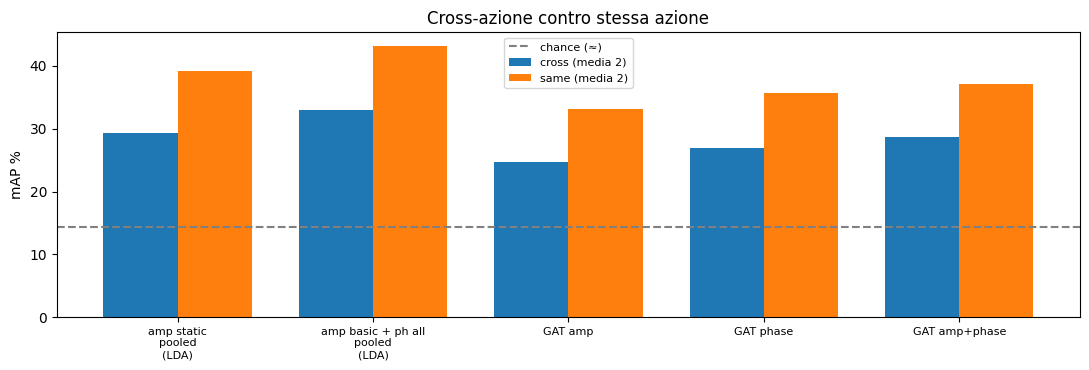

In [7]:
n_f = CFG['neural_folds'] or len(folds)
full = {k: v[:n_f] for k, v in store.items()}          # stessi fold per feature e rete
if CFG['run_neural']:
    for rn in run_names:
        res = [neural_res[(rn, f, CFG['n_epochs'])] for f in range(n_f) if (rn, f, CFG['n_epochs']) in neural_res]
        if res: full[rn + ('' if len(res) == len(folds) else f' [solo {len(res)} fold]')] = res

base_name = 'amp basic + ph all | pooled (LDA)'
tab = results_table(full)
print('Chance mAP media4: %.1f' % chance_mean4)
display(tab)

best_lda = tab.drop(index='CHANCE').loc[[i for i in tab.index if '|' in i]].sort_values('mAP media4', ascending=False).head(1)
print('\nMigliore feature+LDA:', best_lda.index[0], f"| mAP media4 {best_lda['mAP media4'].iloc[0]}  gap {best_lda['gap (same-cross) mAP'].iloc[0]}")

sel = [i for i in tab.index if i != 'CHANCE' and (i.startswith('GAT') or i in (base_name, 'amp static | pooled (LDA)'))]
if sel:
    fig, ax = plt.subplots(figsize=(11, 3.8)); x = np.arange(len(sel)); w = 0.38
    cross_m = [np.mean([tab.loc[i, 'cross mAP'], tab.loc[i, 'cross_rev mAP']]) for i in sel]
    same_m = [np.mean([tab.loc[i, f'same_{GAL} mAP'], tab.loc[i, f'same_{PRB} mAP']]) for i in sel]
    ax.bar(x - w / 2, cross_m, w, label='cross (media 2)'); ax.bar(x + w / 2, same_m, w, label='same (media 2)')
    ax.axhline(14.4, color='gray', ls='--', label='chance (≈)'); ax.set_xticks(x); ax.set_xticklabels([s.replace(' | ', '\n').replace(' (', '\n(') for s in sel], fontsize=8)
    ax.set_ylabel('mAP %'); ax.set_title('Cross-azione contro stessa azione'); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 8. Come leggere i risultati

* **§4:** la riga che conta è la **gap** insieme a `cross`: se `centra per azione`, `z per azione` o la rimozione del sottospazio alzano `cross`/`cross_rev` senza abbassare `same_*`, il cambio di azione è almeno in parte un effetto *lineare* sistematico, correggibile. Confronta sempre la rimozione con il **controllo** a direzioni casuali: se costano uguale, la rimozione non fa nulla di specifico.
* **§6/§7, GAT:** il baseline da battere è `amp basic + ph all | pooled (LDA)` (≈ 38 mAP media4). Se `GAT amp+phase` supera sia `GAT amp` sia `GAT phase`, ampiezza e fase si completano; se `GAT phase` ≈ `GAT amp+phase`, l'informazione utile è nella fase.
* **Bilanciati contro non bilanciati** (`include_unbalanced_ablation=True`): se i bilanciati riducono il gap cross, l'esposizione all'azione in training è la leva giusta.
* Con 4 fold e circa 220 query per protocollo, differenze sotto 3 punti non sono significative. Una rete che resta sotto LDA con 33 identità conferma che i dati sono pochi per un modello profondo; in quel caso il risultato utile per la relazione è proprio questo confronto.
* Se il tempo è un problema: `neural_runs=['GAT amp+phase']`, `neural_folds=2`, `n_epochs=25` (i risultati con meno fold vanno confrontati solo con le stesse fold).